# 04 — Model Training, Validation & Evaluation
**Goal:** Train 4 regression models to estimate expected `AC_POWER`, compare them on **Validation**, evaluate the winner on **Test**, and save it for Inference & Loss Analysis.

Models we compare:
1. **Linear Regression** (baseline, with `StandardScaler`)
2. **Random Forest**
3. **Gradient Boosting** (`HistGradientBoostingRegressor`)
4. **XGBoost** (`XGBRegressor`)


## 1. Load Train, Validation & Test Sets

In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from xgboost import XGBRegressor

sns.set_theme(style="whitegrid")

train = pd.read_csv("../data/processed/train.csv", parse_dates=["DATE_TIME"])
val   = pd.read_csv("../data/processed/val.csv",   parse_dates=["DATE_TIME"])
test  = pd.read_csv("../data/processed/test.csv",  parse_dates=["DATE_TIME"])

features = [
    "IRRADIATION", "MODULE_TEMPERATURE", "AMBIENT_TEMPERATURE", "TEMP_DIFF",
    "relative_humidity_2m", "cloud_cover", "wind_speed_10m", "HOUR_SIN", "HOUR_COS"
]
target = "AC_POWER"

X_train, y_train = train[features].astype(np.float32), train[target].astype(np.float32)
X_val,   y_val   = val[features].astype(np.float32),   val[target].astype(np.float32)
X_test,  y_test  = test[features].astype(np.float32),  test[target].astype(np.float32)

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)


Train: (53338, 9) | Val: (11968, 9) | Test: (11792, 9)


## 2. Simple Evaluation Function
Every model is judged by the same 3 metrics on **Train** (to check overfitting) and **Validation** (to pick the winner):
- **MAE** (lower is better)
- **RMSE** (lower is better)
- **R²** (higher is better, max = 1.0)

In [2]:
results = []
trained_models = {}

def train_and_evaluate(name, model):
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    val_pred   = model.predict(X_val)

    row = {
        "Model": name,
        "Train_MAE":  round(mean_absolute_error(y_train, train_pred), 2),
        "Val_MAE":    round(mean_absolute_error(y_val, val_pred), 2),
        "Train_RMSE": round(root_mean_squared_error(y_train, train_pred), 2),
        "Val_RMSE":   round(root_mean_squared_error(y_val, val_pred), 2),
        "Train_R2":   round(r2_score(y_train, train_pred), 4),
        "Val_R2":     round(r2_score(y_val, val_pred), 4),
    }
    results.append(row)
    trained_models[name] = model
    print(f"{name:20s} | Train/Val MAE: {row['Train_MAE']:6.2f}/{row['Val_MAE']:6.2f} | Train/Val RMSE: {row['Train_RMSE']:6.2f}/{row['Val_RMSE']:6.2f} | Train/Val R2: {row['Train_R2']:.4f}/{row['Val_R2']:.4f}")


## 3. Train All 4 Models

In [3]:
# Model 1: Linear Regression (needs StandardScaler)
lr = make_pipeline(StandardScaler(), LinearRegression())
train_and_evaluate("Linear Regression", lr)


Linear Regression    | Train/Val MAE: 138.14/115.58 | Train/Val RMSE: 240.04/202.81 | Train/Val R2: 0.6487/0.6765


In [4]:
# Model 2: Random Forest
rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=1)
train_and_evaluate("Random Forest", rf)


Random Forest        | Train/Val MAE:  95.62/ 92.44 | Train/Val RMSE: 205.45/191.38 | Train/Val R2: 0.7427/0.7120


In [5]:
# Model 3: Gradient Boosting (scikit-learn)
gb = HistGradientBoostingRegressor(max_depth=6, learning_rate=0.05, max_iter=200, random_state=42)
train_and_evaluate("Gradient Boosting", gb)


Gradient Boosting    | Train/Val MAE:  98.45/ 86.69 | Train/Val RMSE: 206.12/181.77 | Train/Val R2: 0.7410/0.7402


In [6]:
# Model 4: XGBoost
xgb = XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.05, random_state=42, n_jobs=1)
train_and_evaluate("XGBoost", xgb)


XGBoost              | Train/Val MAE:  94.79/ 87.53 | Train/Val RMSE: 203.38/182.25 | Train/Val R2: 0.7478/0.7388


## 4. Compare All 4 Models (Table & Visual Charts)

,Model,Train_MAE,Val_MAE,Train_RMSE,Val_RMSE,Train_R2,Val_R2
0,Gradient Boosting,98.45,86.69,206.12,181.77,0.7410,0.7402
1,XGBoost,94.79,87.53,203.38,182.25,0.7478,0.7388
2,Random Forest,95.62,92.44,205.45,191.38,0.7427,0.7120
3,Linear Regression,138.14,115.58,240.04,202.81,0.6487,0.6765


C:\Users\hp\AppData\Local\Temp\ipykernel_25448\93841040.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Val_MAE", y="Model", palette="viridis", ax=axes[0])
C:\Users\hp\AppData\Local\Temp\ipykernel_25448\93841040.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Val_R2", y="Model", palette="magma", ax=axes[1])


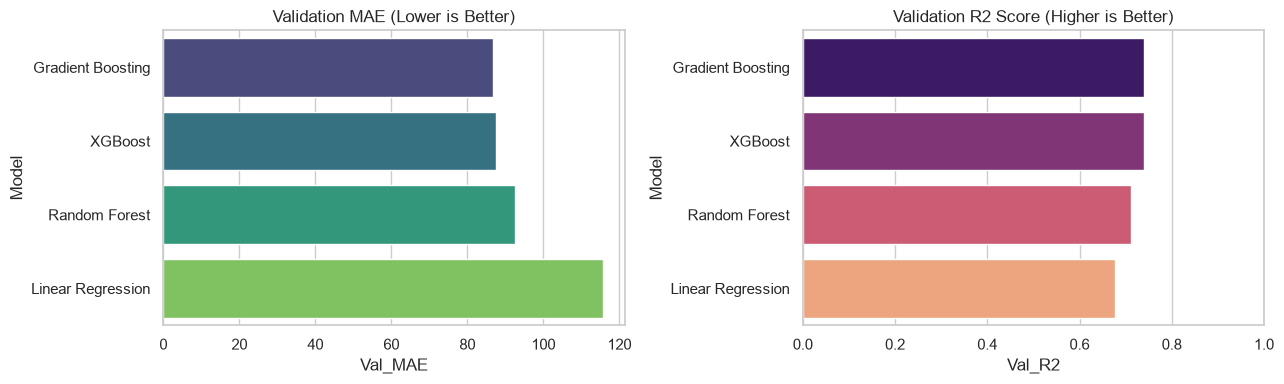

In [7]:
results_df = pd.DataFrame(results).sort_values("Val_MAE").reset_index(drop=True)
display(results_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.barplot(data=results_df, x="Val_MAE", y="Model", palette="viridis", ax=axes[0])
axes[0].set_title("Validation MAE (Lower is Better)")

sns.barplot(data=results_df, x="Val_R2", y="Model", palette="magma", ax=axes[1])
axes[1].set_title("Validation R2 Score (Higher is Better)")
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()


## 5. Final Evaluation on the Untouched Test Set
Let's evaluate all 4 models on `test.csv` for comparison, and plot detailed diagnostics for the winning model.

In [8]:
test_rows = []
for name, model in trained_models.items():
    pred = model.predict(X_test)
    test_rows.append({
        "Model": name,
        "Test_MAE":  round(mean_absolute_error(y_test, pred), 2),
        "Test_RMSE": round(root_mean_squared_error(y_test, pred), 2),
        "Test_R2":   round(r2_score(y_test, pred), 4),
    })

test_results_df = pd.DataFrame(test_rows).sort_values("Test_MAE").reset_index(drop=True)
display(test_results_df)

best_name = results_df.loc[0, "Model"]
best_model = trained_models[best_name]
test_pred = best_model.predict(X_test)
print(f"\nWinning Model (selected on Validation): {best_name}")


,Model,Test_MAE,Test_RMSE,Test_R2
0,Gradient Boosting,86.50,178.80,0.7394
1,Random Forest,88.77,183.37,0.7259
2,XGBoost,90.42,181.70,0.7309
3,Linear Regression,122.67,193.70,0.6942



Winning Model (selected on Validation): Gradient Boosting


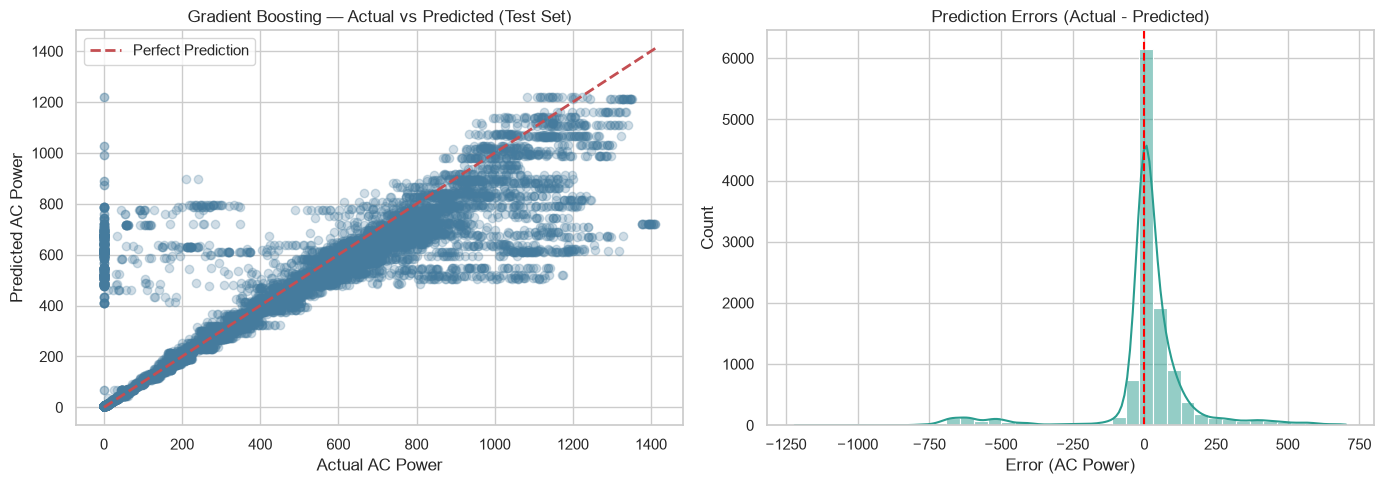

In [9]:
# Visual check: Actual vs Predicted + Error Distribution (Residuals)
errors = y_test - test_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Actual vs Predicted scatter
axes[0].scatter(y_test, test_pred, alpha=0.25, color="#457b9d")
axes[0].plot([0, y_test.max()], [0, y_test.max()], "r--", linewidth=2, label="Perfect Prediction")
axes[0].set_title(f"{best_name} — Actual vs Predicted (Test Set)")
axes[0].set_xlabel("Actual AC Power")
axes[0].set_ylabel("Predicted AC Power")
axes[0].legend()

# 2. Residuals histogram
sns.histplot(errors, bins=40, kde=True, color="#2a9d8f", ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Prediction Errors (Actual - Predicted)")
axes[1].set_xlabel("Error (AC Power)")

plt.tight_layout()
plt.show()


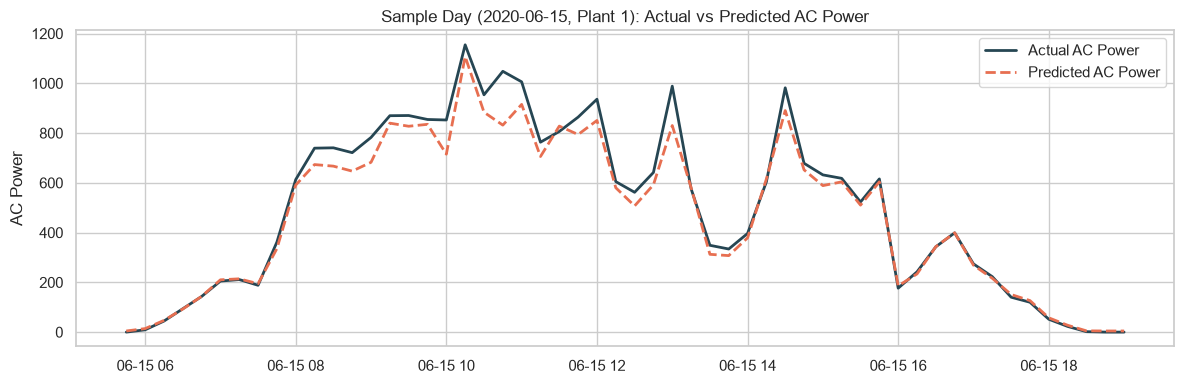

In [10]:
# Visual check: One single day (Plant 1 average) — Actual vs Predicted curve
test_plot = test.copy()
test_plot["PREDICTED_AC_POWER"] = test_pred

one_day = test_plot[(test_plot["PLANT_ID"] == 4135001) & (test_plot["DATE_TIME"].dt.date == pd.to_datetime("2020-06-15").date())]
one_day_avg = one_day.groupby("DATE_TIME")[["AC_POWER", "PREDICTED_AC_POWER"]].mean()

plt.figure(figsize=(12, 4))
plt.plot(one_day_avg.index, one_day_avg["AC_POWER"], label="Actual AC Power", linewidth=2, color="#264653")
plt.plot(one_day_avg.index, one_day_avg["PREDICTED_AC_POWER"], label="Predicted AC Power", linewidth=2, linestyle="--", color="#e76f51")
plt.title("Sample Day (2020-06-15, Plant 1): Actual vs Predicted AC Power")
plt.ylabel("AC Power")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Save All 4 Trained Models
We save all 4 models into `models/` (plus a copy of the winner as `best_solar_model.joblib`) so you can compare or use any of them later.

In [11]:
os.makedirs("../models", exist_ok=True)

for name, model in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    path = os.path.join("../models", filename)
    joblib.dump(model, path)
    print("Saved:", path)

# Also save the winning model under a standard name
joblib.dump(best_model, "../models/best_solar_model.joblib")
print("Saved winner as: ../models/best_solar_model.joblib")


Saved: ../models\linear_regression.joblib
Saved: ../models\random_forest.joblib
Saved: ../models\gradient_boosting.joblib
Saved: ../models\xgboost.joblib
Saved winner as: ../models/best_solar_model.joblib
